In [14]:
import re 
import matplotlib.pyplot as plt
import tiktoken
import numpy as np
text_path = "../data/extracted/labor_law_cleaned.txt"

with open(text_path, "r", encoding="utf-8") as file:
    text = file.read()

print(len(text))

Matplotlib is building the font cache; this may take a moment.


189268


In [8]:
chapters=re.findall(
    r'^\s*Chương\s+[IVXLCDM]+\s*$',
    text,
    flags=re.MULTILINE
)

articles = re.findall(
    r'^Điều\s+\d+\.',
    text,
    flags=re.MULTILINE
)

sections = re.findall(
    r'^Mục\s+\d+\.',
    text,
    flags=re.MULTILINE
)

print("Chương:", len(chapters))
print("Mục:", len(sections))
print("Điều:", len(articles))

Chương: 17
Mục: 24
Điều: 220


In [9]:
pattern = r'(Điều\s+\d+\..*?)(?=^Điều\s+\d+\.|\Z)'
articles = re.findall(
    pattern,
    text,
    flags=re.MULTILINE | re.DOTALL
)
print(articles[1][:500])

Điều 2. Đối tượng áp dụng
1. Người lao động, người học nghề, người tập nghề và người làm việc không có quan hệ lao động.
2. Người sử dụng lao động.
3. Người lao động nước ngoài làm việc tại Việt Nam.
4. Cơ quan, tổ chức, cá nhân khác có liên quan trực tiếp đến quan hệ lao động.



In [10]:
min_idx = min(
    range(len(articles)),
    key=lambda i: len(articles[i])
)

max_idx = max(
    range(len(articles)),
    key=lambda i: len(articles[i])
)

print("Điều ngắn nhất:")
print(articles[min_idx][:200])

print("\nĐộ dài:", len(articles[min_idx]))

print("\nĐiều dài nhất:")
print(articles[max_idx][:200])

print("\nĐộ dài:", len(articles[max_idx]))

Điều ngắn nhất:
Điều 106. Giờ làm việc ban đêm
Giờ làm việc ban đêm được tính từ 22 giờ đến 06 giờ sáng ngày hôm sau.


Độ dài: 102

Điều dài nhất:
Điều 219. Sửa đổi, bổ sung một số điều của các luật có liên quan đến lao động
1. Sửa đổi, bổ sung một số điều của Luật Bảo hiểm xã hội số 58/2014/QH13 đã được sửa đổi, bổ sung theo Luật số
84/2015/QH1

Độ dài: 7248


[ 356.5   548.    798.1   897.4  1415.16]


C:\Users\vietl\AppData\Local\Temp\ipykernel_2100\3785827501.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(token_lengths, vert=False)


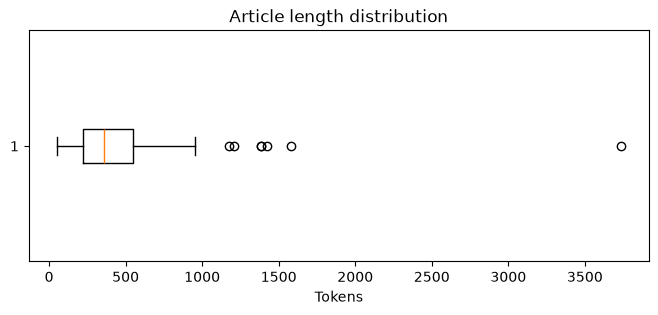

In [20]:

enc = tiktoken.get_encoding("cl100k_base")

token_lengths = [
    len(enc.encode(article))
    for article in articles
]


print(np.percentile(token_lengths, [50,75,90,95,99]))
plt.figure(figsize=(8,3))
plt.boxplot(token_lengths, vert=False)

plt.xlabel("Tokens")
plt.title("Article length distribution")

plt.show()

In [21]:
for threshold in [256, 512, 1024, 2048]:
    count = sum(
        x > threshold
        for x in token_lengths
    )

    print(
        threshold,
        count,
        f"({count/len(token_lengths)*100:.1f}%)"
    )

256 151 (68.6%)
512 69 (31.4%)
1024 7 (3.2%)
2048 1 (0.5%)


Chỉ có 1 điều luật vượt quá 2048 token

In [23]:
import pandas as pd

lines = [line.strip() for line in text.splitlines() if line.strip()]

chapters = []
articles = []

current_chapter = None
current_chapter_title = None

current_section = None
current_section_title = None

article_start_idx = []

# =========================
# Tìm vị trí các Điều
# =========================

for i, line in enumerate(lines):
    if re.match(r'^Điều\s+\d+\.', line):
        article_start_idx.append(i)

article_start_idx.append(len(lines))

# =========================
# Parse Chương / Mục
# =========================

chapter_map = {}
section_map = {}

for i, line in enumerate(lines):

    if re.match(r'^Chương\s+[IVXLCDM]+$', line):

        roman = re.search(
            r'^Chương\s+([IVXLCDM]+)$',
            line
        ).group(1)

        title = ""

        if i + 1 < len(lines):
            title = lines[i + 1]

        current_chapter = roman
        current_chapter_title = title

        chapter_map[i] = (
            current_chapter,
            current_chapter_title
        )

    elif re.match(r'^Mục\s+\d+\.', line):

        m = re.match(
            r'^Mục\s+(\d+)\.\s*(.*)$',
            line
        )

        current_section = m.group(1)
        current_section_title = m.group(2)

        section_map[i] = (
            current_section,
            current_section_title
        )

# =========================
# Parse Điều
# =========================

current_chapter = None
current_chapter_title = None

current_section = None
current_section_title = None

for idx in range(len(article_start_idx)-1):

    start = article_start_idx[idx]
    end = article_start_idx[idx+1]

    # tìm chapter gần nhất phía trên
    for pos in sorted(chapter_map.keys()):
        if pos < start:
            current_chapter, current_chapter_title = chapter_map[pos]

    # tìm section gần nhất phía trên
    for pos in sorted(section_map.keys()):
        if pos < start:
            current_section, current_section_title = section_map[pos]

    article_lines = lines[start:end]

    article_text = "\n".join(article_lines)

    first_line = article_lines[0]

    m = re.match(
        r'^Điều\s+(\d+)\.\s*(.*)$',
        first_line
    )

    article_id = int(m.group(1))
    article_title = m.group(2)

    clauses = re.findall(
        r'^\d+\.',
        article_text,
        flags=re.MULTILINE
    )

    points = re.findall(
        r'^[a-z]\)',
        article_text,
        flags=re.MULTILINE
    )

    articles.append({
        "article_id": article_id,
        "article_title": article_title,

        "chapter_id": current_chapter,
        "chapter_title": current_chapter_title,

        "section_id": current_section,
        "section_title": current_section_title,

        "chars": len(article_text),
        "words": len(article_text.split()),

        "num_clauses": len(clauses),
        "num_points": len(points),

        "content": article_text
    })

# =========================
# Parse Chapters
# =========================

chapter_positions = sorted(chapter_map.keys())

for i, pos in enumerate(chapter_positions):

    chapter_id, chapter_title = chapter_map[pos]

    next_pos = (
        chapter_positions[i+1]
        if i < len(chapter_positions)-1
        else len(lines)
    )

    chapter_text = "\n".join(
        lines[pos:next_pos]
    )

    chapter_articles = [
        a for a in articles
        if a["chapter_id"] == chapter_id
    ]

    chapter_sections = set(
        a["section_id"]
        for a in chapter_articles
        if a["section_id"] is not None
    )

    chapters.append({
        "chapter_id": chapter_id,
        "chapter_title": chapter_title,

        "num_sections": len(chapter_sections),
        "num_articles": len(chapter_articles),

        "chars": len(chapter_text),
        "words": len(chapter_text.split()),

        "content": chapter_text
    })

# =========================
# Export Excel
# =========================

chapters_df = pd.DataFrame(chapters)
articles_df = pd.DataFrame(articles)

with pd.ExcelWriter(
    "../data/extracted/labor_law_eda.xlsx",
    engine="openpyxl"
) as writer:

    chapters_df.to_excel(
        writer,
        sheet_name="Chapters",
        index=False
    )

    articles_df.to_excel(
        writer,
        sheet_name="Articles",
        index=False
    )

C:\Users\vietl\AppData\Local\Temp\ipykernel_2100\2817612816.py:196: UserWarning: Cell contents too long (39883), truncated to 32767 characters
  chapters_df.to_excel(


In [10]:
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
import time

options = Options()
options.add_argument("--start-maximized")

driver = webdriver.Chrome(options=options)

driver.get(
    "https://thuvienphapluat.vn/van-ban/Lao-dong-Tien-luong/Bo-Luat-lao-dong-2019-333670.aspx"
)

time.sleep(10)

html = driver.page_source

print("Điều 1" in html)
print(html[:1000])

True
<html xmlns="http://www.w3.org/1999/xhtml"><head id="ctl00_Head1"><meta http-equiv="origin-trial" content="A7vZI3v+Gz7JfuRolKNM4Aff6zaGuT7X0mf3wtoZTnKv6497cVMnhy03KDqX7kBz/q/iidW7srW31oQbBt4VhgoAAACUeyJvcmlnaW4iOiJodHRwczovL3d3dy5nb29nbGUuY29tOjQ0MyIsImZlYXR1cmUiOiJEaXNhYmxlVGhpcmRQYXJ0eVN0b3JhZ2VQYXJ0aXRpb25pbmczIiwiZXhwaXJ5IjoxNzU3OTgwODAwLCJpc1N1YmRvbWFpbiI6dHJ1ZSwiaXNUaGlyZFBhcnR5Ijp0cnVlfQ=="><link rel="icon" href="https://cdn.thuvienphapluat.vn/images/icon/favicon.ico" type="image/x-icon"><link rel="shortcut icon" href="https://cdn.thuvienphapluat.vn/images/icon/favicon.ico" type="image/x-icon"><link rel="icon" type="image/png" sizes="16x16" href="https://cdn.thuvienphapluat.vn/images/icon/favicon-16x16.png"><link rel="icon" type="image/png" sizes="32x32" href="https://cdn.thuvienphapluat.vn/images/icon/favicon-32x32.png"><link rel="icon" type="image/png" sizes="48x48" href="https://cdn.thuvienphapluat.vn/images/icon/favicon-48x48.png"><link rel="icon" type="image/png" sizes

In [ ]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(driver.page_source, "html.parser")

text = soup.get_text("\n")

for key in [
    "Điều 1",
    "Điều 13",
    "Chương I",
    "Hợp đồng lao động"
]:
    print(key, key in text)

Điều 1 True
Điều 13 True
Chương I True
Hợp đồng lao động True


In [13]:
import re

articles = re.findall(r"Điều\s+\d+", text)

print("Số điều:", len(articles))
print(articles[:20])

Số điều: 608
['Điều 9', 'Điều 29', 'Điều 97', 'Điều 1', 'Điều 2', 'Điều 3', 'Điều 4', 'Điều 5', 'Điều 6', 'Điều 7', 'Điều 8', 'Điều 9', 'Điều 10', 'Điều 11', 'Điều 12', 'Điều 13', 'Điều 14', 'Điều 15', 'Điều 4', 'Điều 16']


In [27]:
html = driver.page_source

print("ndtemp" in html)
print("bmContent" in html)
print("bmContentOld" in html)

True
True
True


In [25]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(driver.page_source, "html.parser")

blocks = soup.select("div.ndtemp")

print("Số popup:", len(blocks))

Số popup: 1


In [26]:
block = soup.select_one("div.ndtemp")

print(block.get_text("\n", strip=True)[:5000])

Nguyên tắc giao kết và thực hiện hợp đồng lao động điện tử được hướng dẫn bởi Điều 4 Nghị định 337/2025/NĐ-CP có hiệu lực từ ngày 01/01/2026
Xem nội dung VB
Căn cứ Bộ luật Lao động số 45/2019/QH14;
...
Chính phủ ban hành Nghị định quy định về hợp đồng lao động điện tử.
...
Điều 4. Nguyên tắc chung
1. Việc giao kết và thực hiện hợp đồng lao động điện tử phải tuân thủ quy định của pháp luật về lao động, về giao dịch điện tử, về an toàn thông tin mạng, về dữ liệu, về bảo vệ dữ liệu cá nhân, về lưu trữ và quy định tại Nghị định này.
2. Hợp đồng lao động điện tử phải được gửi cho người lao động và người sử dụng lao động dưới hình thức thông điệp dữ liệu thông qua phương tiện điện tử phù hợp theo thỏa thuận của các bên.
3. Khuyến khích sử dụng hợp đồng lao động điện tử thay thế cho hợp đồng lao động bằng văn bản giấy trong quản trị nhân sự của người sử dụng lao động, trong giải quyết thủ tục hành chính liên quan đến hợp đồng lao động.
Xem nội dung VB
Điều 15. Nguyên tắc giao kết hợp đồng lao

In [29]:
import re

html = driver.page_source

tips = set(re.findall(r"lqhlTip-\d+", html))

print("Số tip:", len(tips))
print(list(tips)[:20])

Số tip: 74
['lqhlTip-2904697', 'lqhlTip-3655577', 'lqhlTip-3271615', 'lqhlTip-2904467', 'lqhlTip-3271613', 'lqhlTip-3365521', 'lqhlTip-3292077', 'lqhlTip-3655733', 'lqhlTip-3655990', 'lqhlTip-2904560', 'lqhlTip-3655617', 'lqhlTip-3271624', 'lqhlTip-3271614', 'lqhlTip-3655960', 'lqhlTip-3271610', 'lqhlTip-2904586', 'lqhlTip-2904820', 'lqhlTip-3271611', 'lqhlTip-3655542', 'lqhlTip-3298606']


In [34]:
from selenium.webdriver.common.by import By
from bs4 import BeautifulSoup
import time

results = []

tips = sorted(set([
    x.split("lqhlTip-")[1]
    for x in re.findall(r"lqhlTip-\d+", driver.page_source)
]))

print("Tips:", len(tips))

for tip in tips:

    try:
        # Mở popup
        driver.execute_script(
            f"LS_Tip_Type_Bookmark('.lqhlTip-{tip}')"
        )

        time.sleep(0.5)

        soup = BeautifulSoup(driver.page_source, "html.parser")

        dialog = soup.select_one("#divltrLienQuanHieuLucTungPhanDialog")

        if dialog:

            title = dialog.select_one(".bmTitle")
            content = dialog.select_one("#bmContent")
            original = dialog.select_one("#bmContentOld")

            results.append({
                "tip": tip,
                "title": title.get_text(" ", strip=True) if title else "",
                "content": content.get_text("\n", strip=True) if content else "",
                "original": original.get_text("\n", strip=True) if original else ""
            })

        # Đóng popup
        try:
            close_btn = driver.find_element(
                By.CSS_SELECTOR,
                ".ui-dialog-titlebar-close"
            )
            close_btn.click()
        except:
            pass

        time.sleep(0.2)

    except Exception as e:
        print("Lỗi:", tip, e)

print("Đã lấy:", len(results))

Tips: 74
Đã lấy: 74


In [35]:
import json

with open("labor_law_tips.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

## Đánh giá về các phần mở rộng của các điều/khoản trong hợp đồng lao động

* Điều 12: đầy đủ
* Điều 13: Mở rộng web khác
* Điều 15: Đầy đủ
* Điều 18: Đầy đủ
* Điều 21: Đầy đủ
* Điều 23: đầy đủ
* Điều 30: đầy đủ
* Điều 33: đầy đủ
* Điều 45: đầy đủ
* Điều 46: đầy đủ  
* Điều 47: đầy đủ  
* Điều 51: đầy đủ
* Điều 96: đầy đủ
* Điều 98: đầy đủ
* Điều 107: đầy đủ
* Điều 113: đầy đủ
* Điều 116: đầy đủ
* Điều 118: đầy đủ
* Điều 141: đầy đủ
* Điều 131: đầy đủ
* Điều 135: đầy đủ
* Điều 145: đầy đủ
* Điều 152: đầy 
* Điều 154: đầy đủ nhưng 3 phần
* Điều 155: đầy đủ nhưng 3 phần
* Điều 157: đầy đủ nhưng 3 phần
* Điều 161: đầy đủ
* Điều 161: mở rộng
* Điều 211: hết hạn
* Điều 217: mở rộng

* Khoản 1 điều 14: Mở rộng web
* Khoản 4 điều 14: Đầy đủ
* Điểm d khoản 1 điều 35: đầy đủ
* Điểm d khoản 2 điều 36: đầy đủ
* Khoản 2 điều 54: Mở rộng
* Điểm a khoản 2 điều 59: hết hạn
* Khoản 3 điều 61: đầy đủ
* Khoản 4 điều 53: mở rộng
* Khoản 4 điều 73: đầy đủ
* Khoản 4 điều 91: đầy đủ
* Khoản 2 điều 92: hết hạn
* Khoản 3 điều 92: Một hết hạn đã có cái thay thế mới
* Khoản 3 Điều 112: hết hạn
* Khoản 5 Điều 119: hết hạn
* Khoản 6 Điều 122: đầy đủ
* Khoản 2 Điều 130: đầy đủ
* Khoản 6 Điều 122: đầy đủ
* Khoản 1 Điều 133: đầy đủ
* Khoản 4 Điều 137: đầy đủ
* Khoản 1 Điều 139: đầy đủ
* Khoản 1 Điều 142: đầy đủ
* Khoản 3 điều 143: đầy đủ
* Khoản 2 điều 146: đầy đủ
* Điểm h Khoản 1 điều 147: đầy đủ nhưng kèm phụ lục
* Điểm đ Khoản 2 điều 147: đầy đủ nhưng kèm phụ lục
* Khoản 3 điều 150: đầy đủ
* Điểm d Khoản 1 điều 151: đầy đủ
* Khoản 8 điều 156: đầy đủ
* Khoản 3 điều 169: đầy đủ nhưng kèm 1 xoá
* Khoản 4 điều 156: đầy đủ nhưng 2 phần
* Khoản 2 điều 184: đầy đủ
* Khoản 6 điều 185: mở rộng
* Khoản 3 điều 202: hết hạn
* Khoản 3 điều 205: hết hạn
* Khoản 2 điều 209: đầy đủ
* Khoản 2 điều 210: đầy đủ
* Khoản 1 điều 219: hết hạn - xoá bỏ
* Điểm b Khoản 2 điều 219: đầy đủ


In [3]:
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
import time

options = Options()
options.add_argument("--start-maximized")

driver = webdriver.Chrome(options=options)

driver.get(
    "https://thuvienphapluat.vn/van-ban/Lao-dong-Tien-luong/Bo-Luat-lao-dong-2019-333670.aspx"
)

time.sleep(5)  # chờ trang load

html = driver.page_source

soup = BeautifulSoup(html, "html.parser")

refs = []



for a in soup.find_all("a"):
    name = a.get("name", "")

    if name.startswith("tc_"):
        print(a.get_text(" ", strip=True))

for r in refs:
    print(r)



In [5]:
print(driver.page_source[:5000])

<html xmlns="http://www.w3.org/1999/xhtml"><head id="ctl00_Head1"><meta http-equiv="origin-trial" content="A7vZI3v+Gz7JfuRolKNM4Aff6zaGuT7X0mf3wtoZTnKv6497cVMnhy03KDqX7kBz/q/iidW7srW31oQbBt4VhgoAAACUeyJvcmlnaW4iOiJodHRwczovL3d3dy5nb29nbGUuY29tOjQ0MyIsImZlYXR1cmUiOiJEaXNhYmxlVGhpcmRQYXJ0eVN0b3JhZ2VQYXJ0aXRpb25pbmczIiwiZXhwaXJ5IjoxNzU3OTgwODAwLCJpc1N1YmRvbWFpbiI6dHJ1ZSwiaXNUaGlyZFBhcnR5Ijp0cnVlfQ=="><link rel="icon" href="https://cdn.thuvienphapluat.vn/images/icon/favicon.ico" type="image/x-icon"><link rel="shortcut icon" href="https://cdn.thuvienphapluat.vn/images/icon/favicon.ico" type="image/x-icon"><link rel="icon" type="image/png" sizes="16x16" href="https://cdn.thuvienphapluat.vn/images/icon/favicon-16x16.png"><link rel="icon" type="image/png" sizes="32x32" href="https://cdn.thuvienphapluat.vn/images/icon/favicon-32x32.png"><link rel="icon" type="image/png" sizes="48x48" href="https://cdn.thuvienphapluat.vn/images/icon/favicon-48x48.png"><link rel="icon" type="image/png" sizes="192

In [38]:
refs = []

for tag in soup.find_all(attrs={"name": True}):
    name = tag["name"]

    if name.startswith("tc_"):
        refs.append(tag.get_text(" ", strip=True))

print("Total:", len(refs))

Total: 118


In [39]:
with open("referencesss.txt", "w", encoding="utf-8") as f:
    for ref in refs:
        f.write(ref + "\n")

print(f"Saved {len(refs)} unique references.")

Saved 118 unique references.


In [37]:
with open("references.txt", "w", encoding="utf-8") as f:
    for ref in refs:
        ref = ref.replace("\n", " ").replace("\r", " ")
        ref = " ".join(ref.split())  # gộp nhiều khoảng trắng thành 1
        ref = ref.replace("của Bộ luật này", "của Bộ luật này\n")
        f.write(ref)

In [1]:
import pandas as pd

df = pd.read_excel("labor_law_eda.xlsx")

print(df.columns.tolist())

['chapter_id', 'chapter_title', 'num_sections', 'num_articles', 'chars', 'words', 'content']
